# Faisalabad: understand the data before modelling

This notebook examines hourly weather, AQI, and UV data for the full **2023-2025 UTC period**. The weather is ERA5 reanalysis; air quality and UV are archived CAMS outputs delivered by Open-Meteo. These are modelled series, not independent station measurements.

The steps move from basic summaries to seasonal patterns and unusual hours. The input CSV is unchanged. The final section records what remains uncertain.

**Scope:** all three years are exploratory data. A future performance test must use a separate, uninspected time period; 2025 should not later be described as an untouched test set.

To reproduce from the repository root, install `requirements-eda.txt`, download the history with `python scripts/audit_history.py --download`, then run this notebook. Figures and tables are generated locally from the audited CSV.


In [1]:
from pathlib import Path
import contextlib
import io
import sys

import pandas as pd
from IPython.display import Image, display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "scripts/eda_faisalabad.py").exists())
sys.path.insert(0, str(ROOT / "scripts"))
from eda_faisalabad import load_data, build_eda, OUT, FIELDS, CORE

df = load_data()  # verifies the audited file fingerprint and hourly grid
with contextlib.redirect_stdout(io.StringIO()):
    facts = build_eda(df)

def show(name):
    display(Image(filename=str(OUT / "figures" / name), width=1100))

print(f"{len(df):,} hourly observations; {len(FIELDS)} numeric variables")
print("Chart times use Asia/Karachi (UTC+5). Raw files keep UTC timestamps.")
display(df.head())

26,304 hourly observations; 9 numeric variables
Chart times use Asia/Karachi (UTC+5). Raw files keep UTC timestamps.


,city,temperature_2m,relative_humidity_2m,precipitation,wind_speed_10m,wind_direction_10m,us_aqi,pm2_5,pm10,uv_index
time_pakistan,,,,,,,,,,
2023-01-01 05:00:00+05:00,Faisalabad,7.8,94,0.0,2.43,279,141,65.9,95.0,0.00
2023-01-01 06:00:00+05:00,Faisalabad,7.4,93,0.0,2.45,258,143,68.7,99.0,0.00
2023-01-01 07:00:00+05:00,Faisalabad,7.8,92,0.0,2.59,242,145,78.0,112.2,0.00
2023-01-01 08:00:00+05:00,Faisalabad,8.6,92,0.0,1.80,236,148,96.4,138.8,0.25
2023-01-01 09:00:00+05:00,Faisalabad,9.3,88,0.0,1.30,238,151,100.6,144.4,0.85


## 1. Rows, columns, and summary statistics

A **row** is one city-hour. A **column** records a measurement or modelled value. A **mean** is the arithmetic average; the **median** is the middle value after sorting. A few large values can pull the mean upward. A **percentile** tells us the value below which a given percentage of observations fall.

For illustration, the numbers 1, 2, and 30 have a mean of 11 but a median of 2. These are toy numbers, not weather observations. In the real dataset, compare the PM2.5 mean and median to see how a high-value tail affects the average.

Direction wraps around a circle, so ordinary means and percentiles of degrees are omitted from the descriptive table. Missing values and zero values are different.


In [2]:
display(pd.read_csv(OUT / "tables/description.csv", index_col=0).round(3))
print("Missing values:")
display(df[list(FIELDS)].isna().sum().to_frame("missing"))

,count,mean,std,min,1%,25%,50%,75%,99%,max
temperature_2m,26304.0,24.959,8.949,2.3,6.00,18.40,26.50,31.80,41.60,45.40
relative_humidity_2m,26304.0,63.297,19.643,9.0,20.00,49.00,65.00,79.00,98.00,100.00
precipitation,26304.0,0.051,0.383,0.0,0.00,0.00,0.00,0.00,1.30,17.80
wind_speed_10m,26304.0,2.053,0.941,0.0,0.28,1.43,2.01,2.55,4.96,8.22
wind_direction_10m,26304.0,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,360.00
us_aqi,26304.0,155.810,51.890,66.0,78.00,119.00,152.00,175.00,326.00,437.00
pm2_5,26304.0,74.149,59.387,3.4,14.20,36.90,54.00,88.20,300.80,461.90
pm10,26304.0,108.649,75.473,3.4,19.80,58.00,86.10,137.40,371.60,741.30
uv_index,26304.0,1.291,2.134,0.0,0.00,0.00,0.00,1.85,8.15,11.05


Missing values:


,missing
temperature_2m,0
relative_humidity_2m,0
precipitation,0
wind_speed_10m,0
wind_direction_10m,0
us_aqi,0
pm2_5,0
pm10,0
uv_index,0


## 2. Distributions: what is common, and what is rare?

A **histogram** groups values into intervals called bins. The horizontal axis is the value; bar height is the number of hours in that interval. The dashed line marks the mean and the dotted line marks the median.

Look for concentration near zero in rain and UV, long upper tails in pollutants, and the difference between a typical value and an extreme. Each panel has its own unit. Raw wind direction gets a circular plot later.


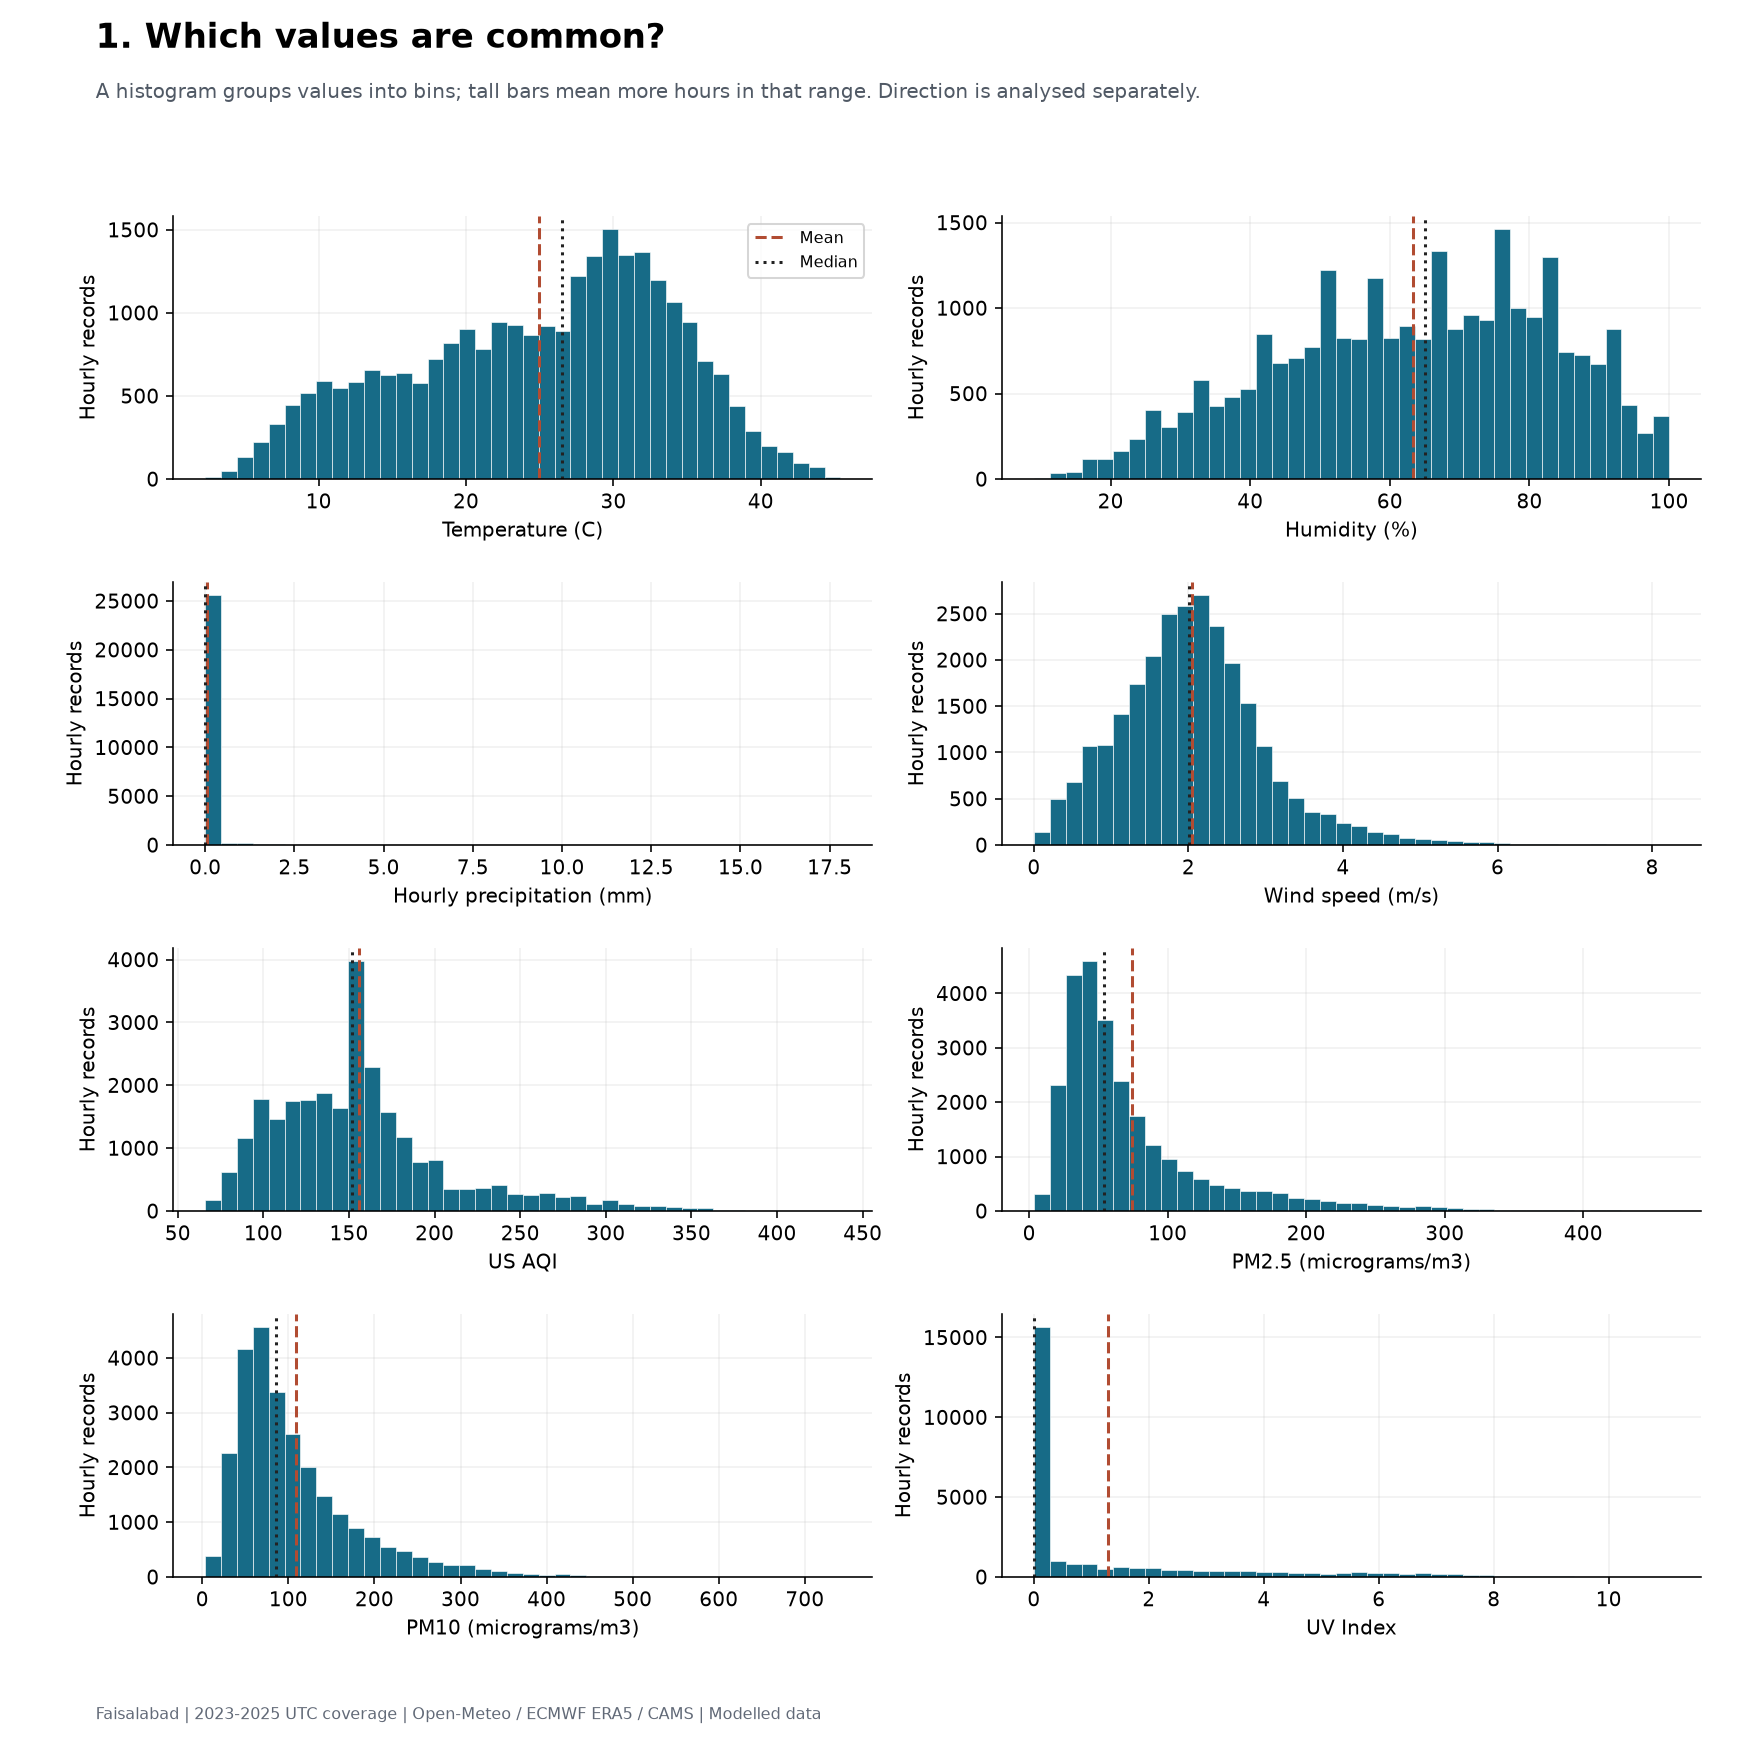

In [3]:
show("01_distributions.png")

## 3. Time series: when do values change?

A **time series** preserves observation order. Daily means smooth the hourly variation so annual patterns are easier to see. Rain is a **daily sum**, because adding hourly amounts gives the day's total; averaging amounts would answer a different question.

Partial local days at the boundaries are excluded from this chart. Smoothing is for display only; the hourly data is retained. One spike in a daily plot may hide a much larger hourly spike.


Complete local days plotted: 1,095


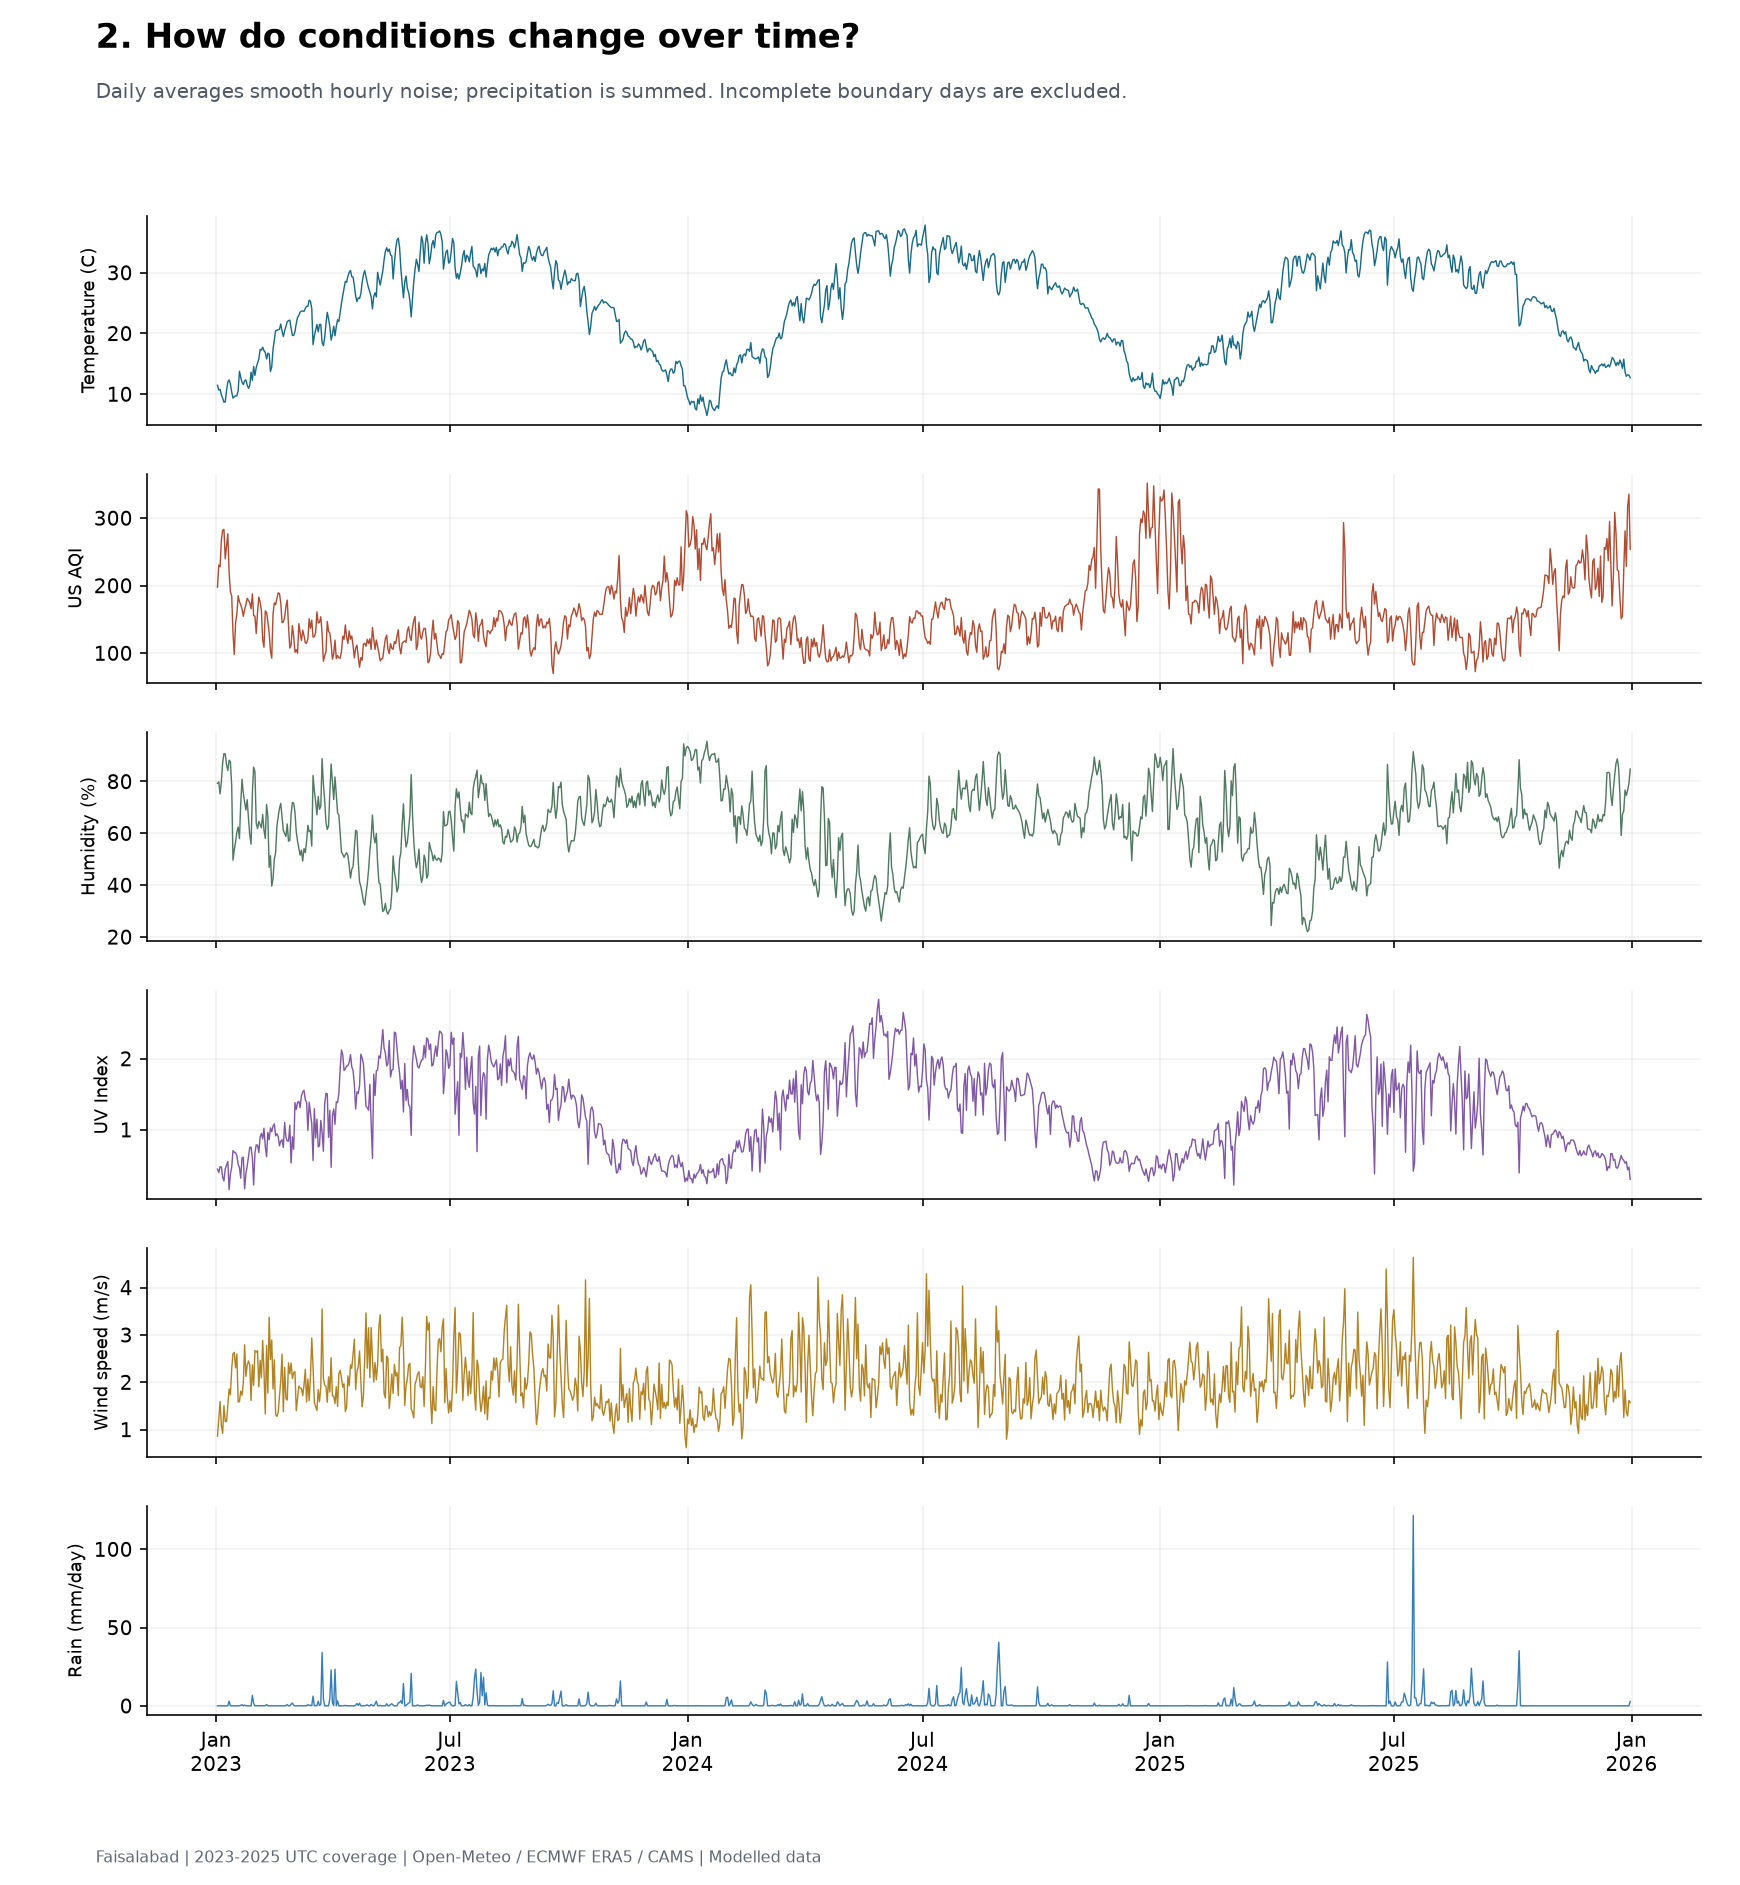

In [4]:
daily = pd.read_csv(OUT / "tables/daily.csv", index_col=0)
print(f"Complete local days plotted: {len(daily):,}")
show("02_daily_series.png")

## 4. Seasonality: compare months

**Seasonality** means a pattern that repeats with a calendar cycle. A **box plot** shows the median and the middle 50% of observations (from Q1 to Q3). The whiskers extend to the most extreme values within 1.5 times the box height from the box edges. Unusual fliers are hidden for readability, but remain in the source data.

Temperature and AQI may have very different seasonal patterns. Rain uses monthly totals by year, which exposes year-to-year differences; only complete local months contribute those totals. A pattern across three years is a limited sample, not proof that future years will match.


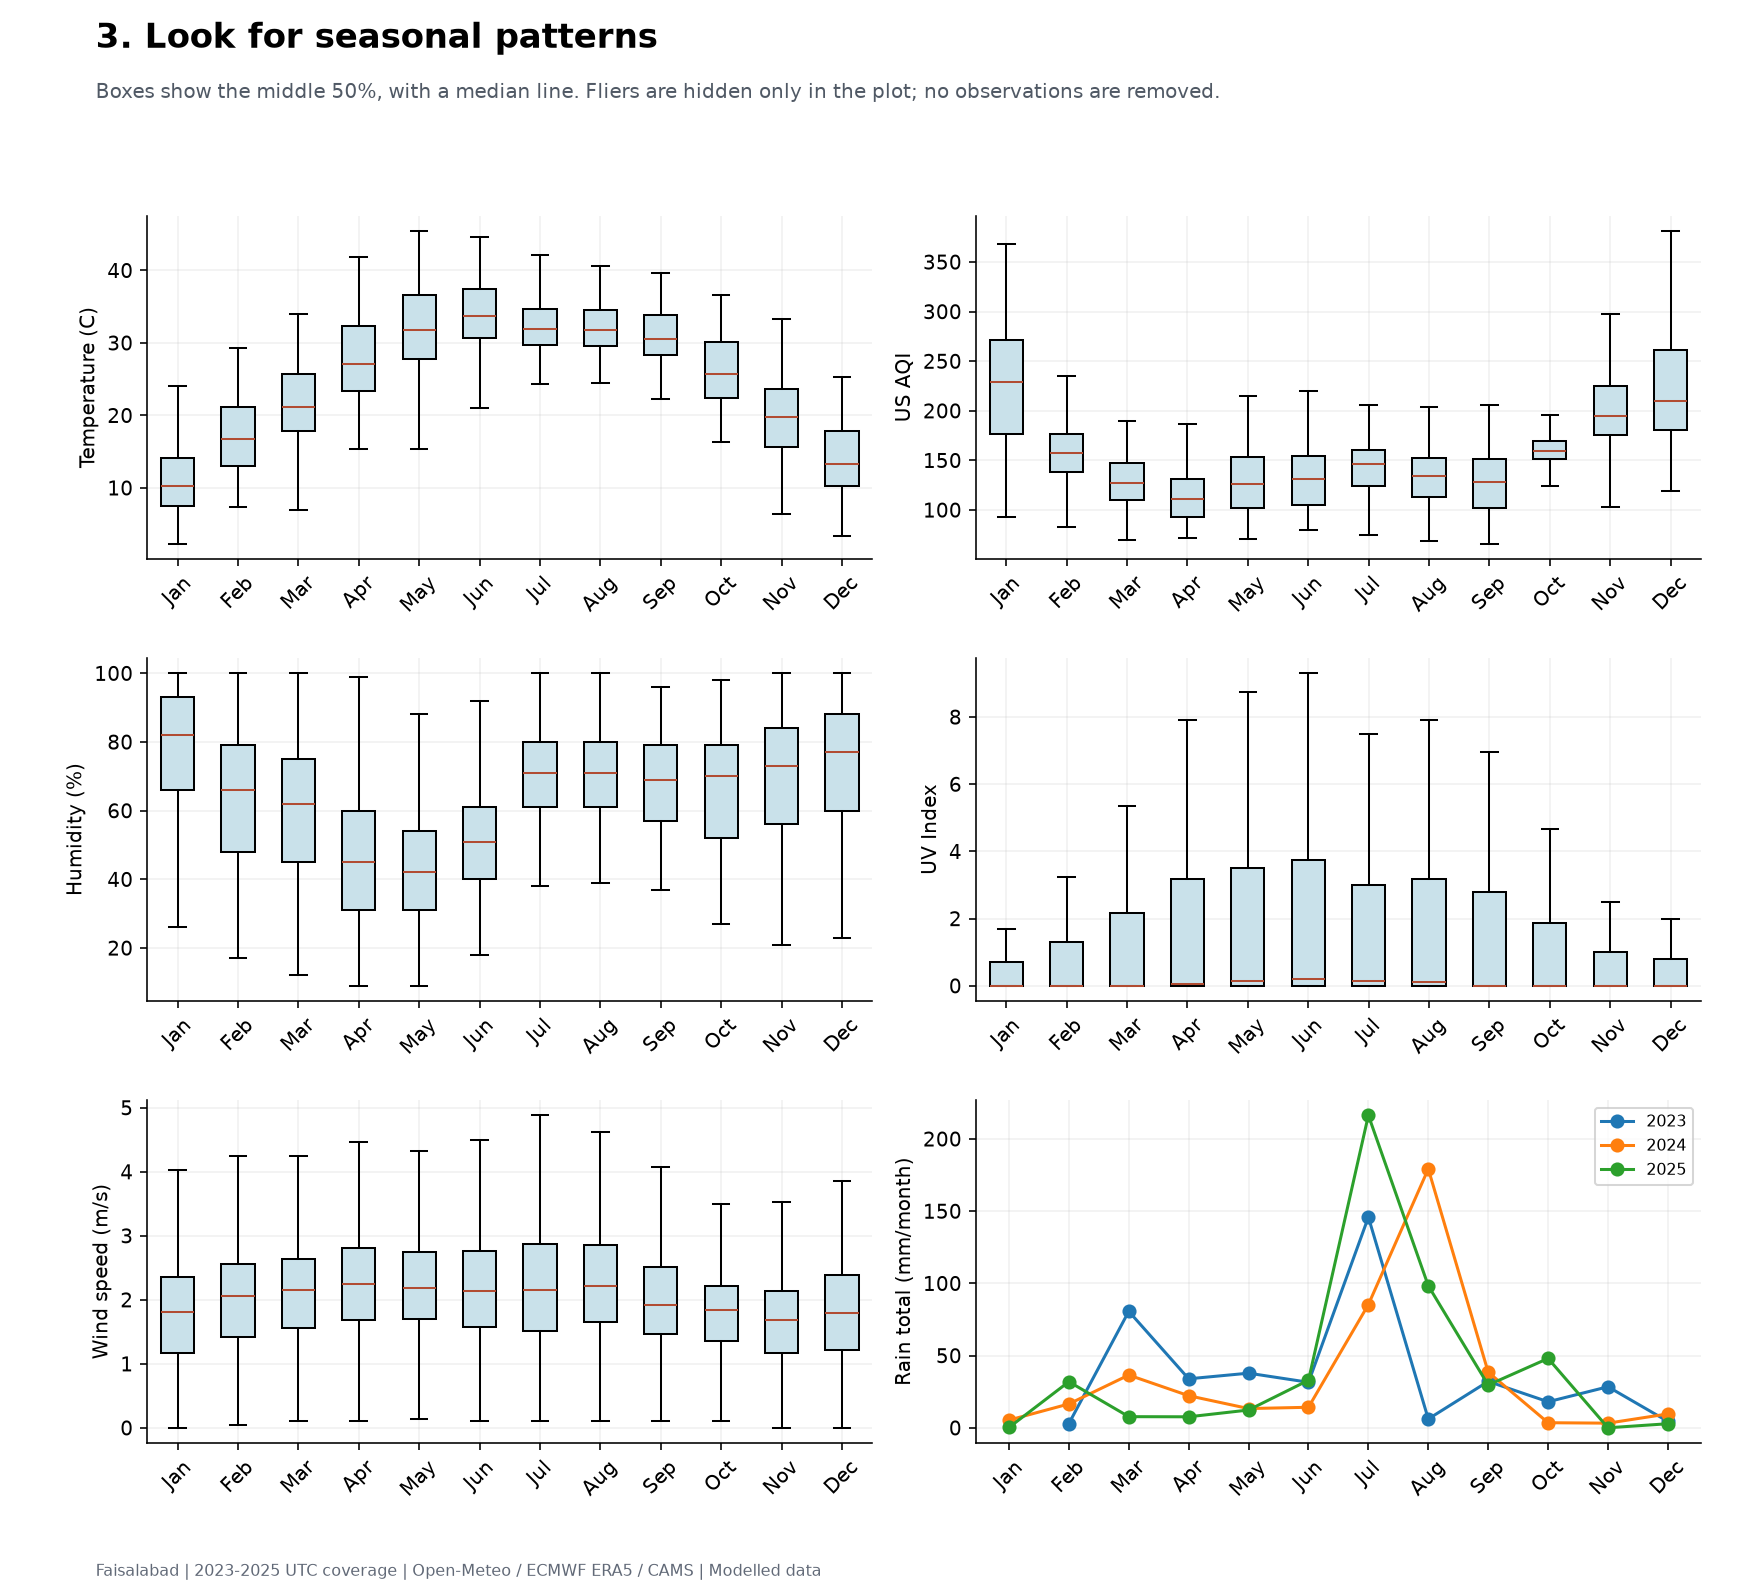

In [5]:
show("03_monthly_patterns.png")

## 5. Daily cycles: hour of day matters

Group records by local hour and average them. This answers, for example, "What is the typical UV value around noon in summer?" Averages hide variation, so these lines are not forecasts or confidence bands.

DJF means December-February, MAM March-May, JJA June-August, and SON September-November. These are convenient calendar groups, not locally estimated season boundaries. The rain panel shows the observed share of hours above an exploratory 0.1 mm threshold.


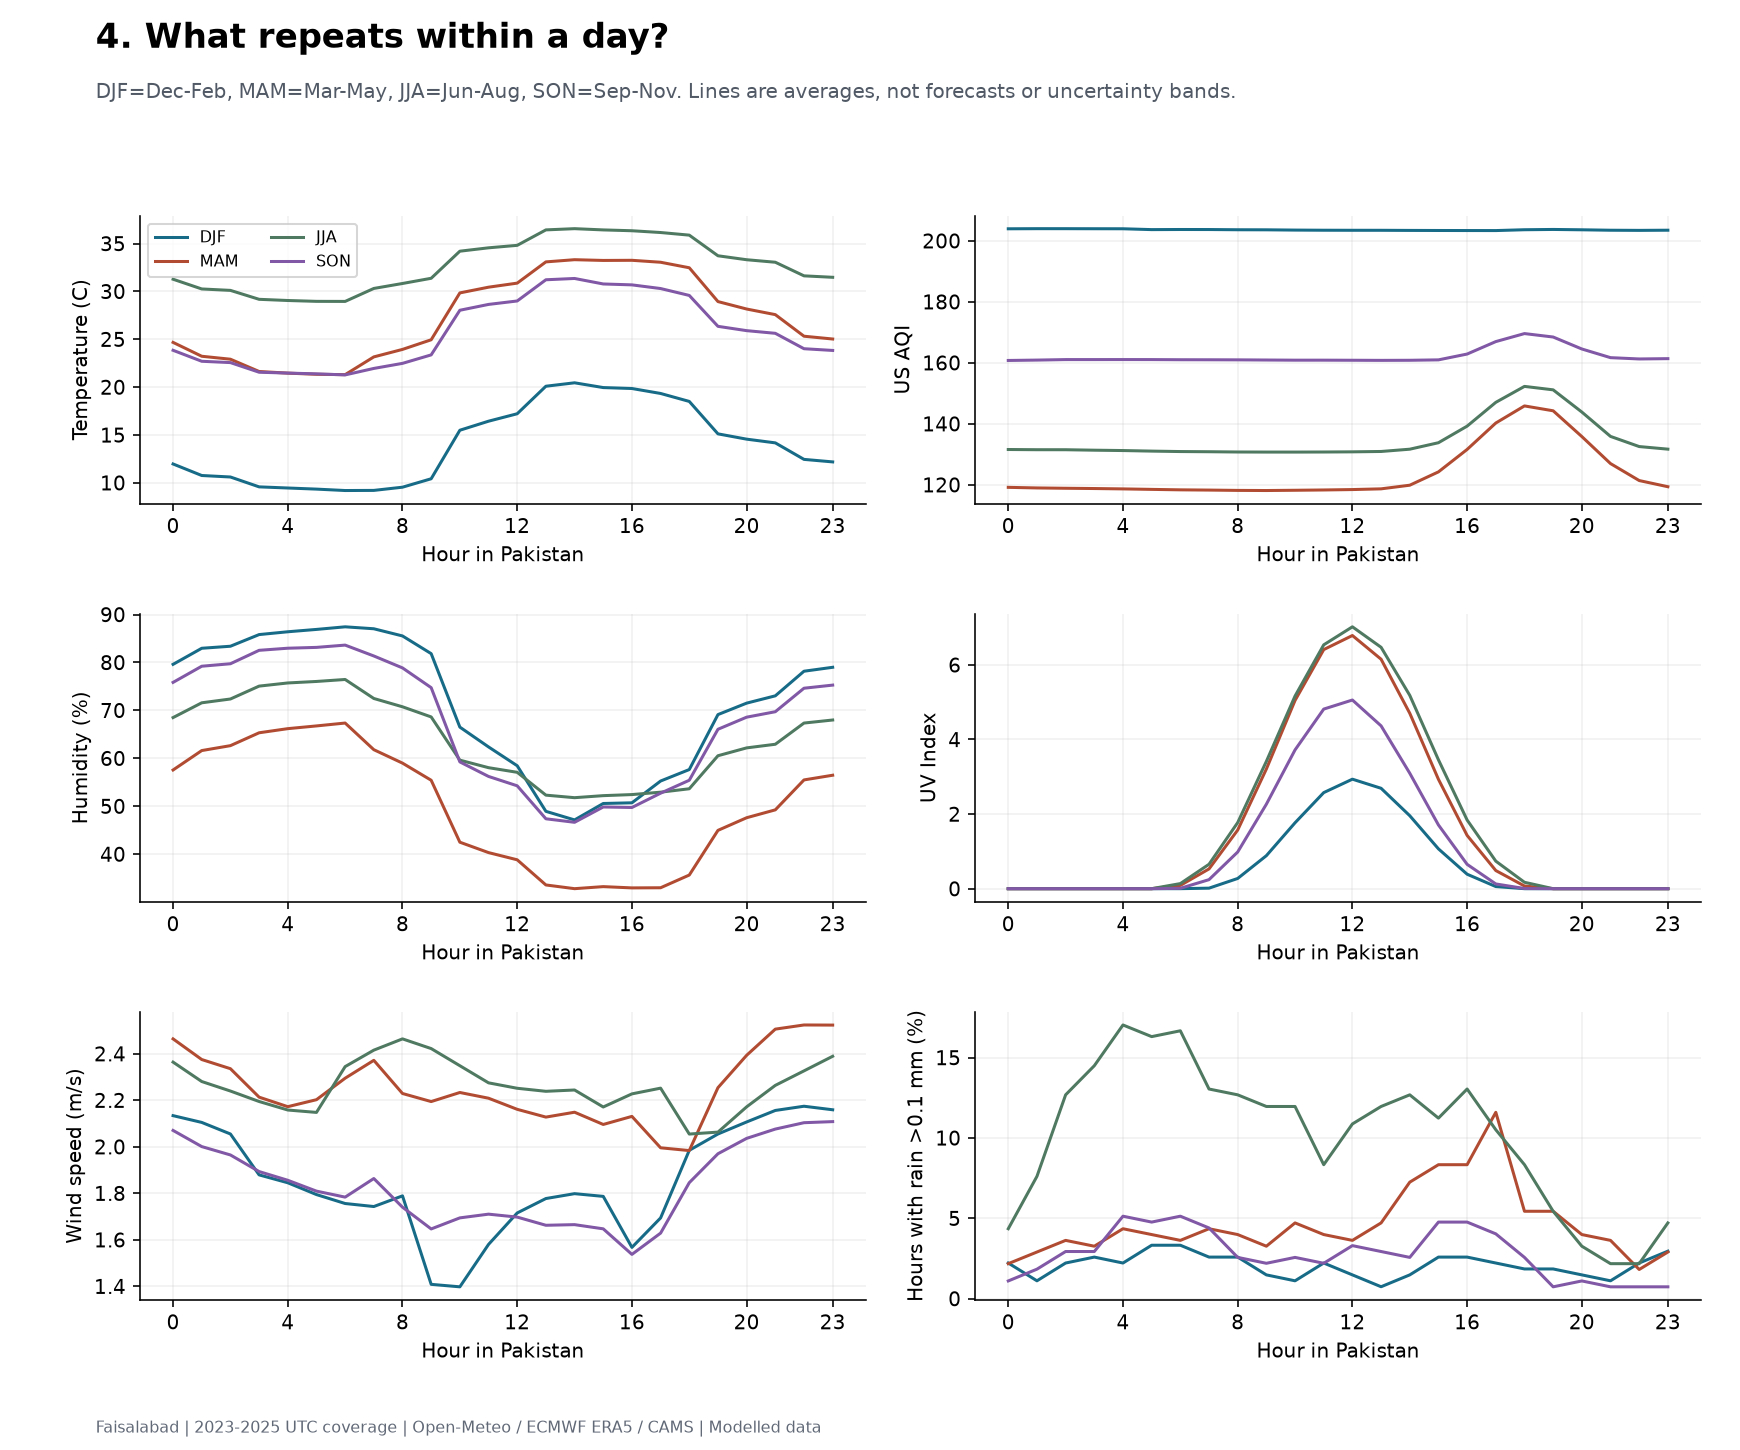

In [6]:
show("04_daily_cycles.png")

## 6. Rain: occurrence, amount, and class imbalance

Predicting **whether** rain occurs is a classification task. Predicting **how much** falls is regression. A probability is a model's estimate between 0 and 1; the historical amount does not contain an observed probability.

**Class imbalance** means one outcome is much more common. If most hours are dry, an always-dry classifier can have high accuracy while missing every wet hour. We compare several candidate event thresholds before choosing one. The positive-rain histogram has a logarithmic count axis: equal vertical distances represent multiplicative changes in counts.


,definition,wet_hours,share_percent
0,amount > 0 mm,2061,7.835
1,amount > 0.1 mm,1295,4.923
2,amount >= 1 mm,388,1.475


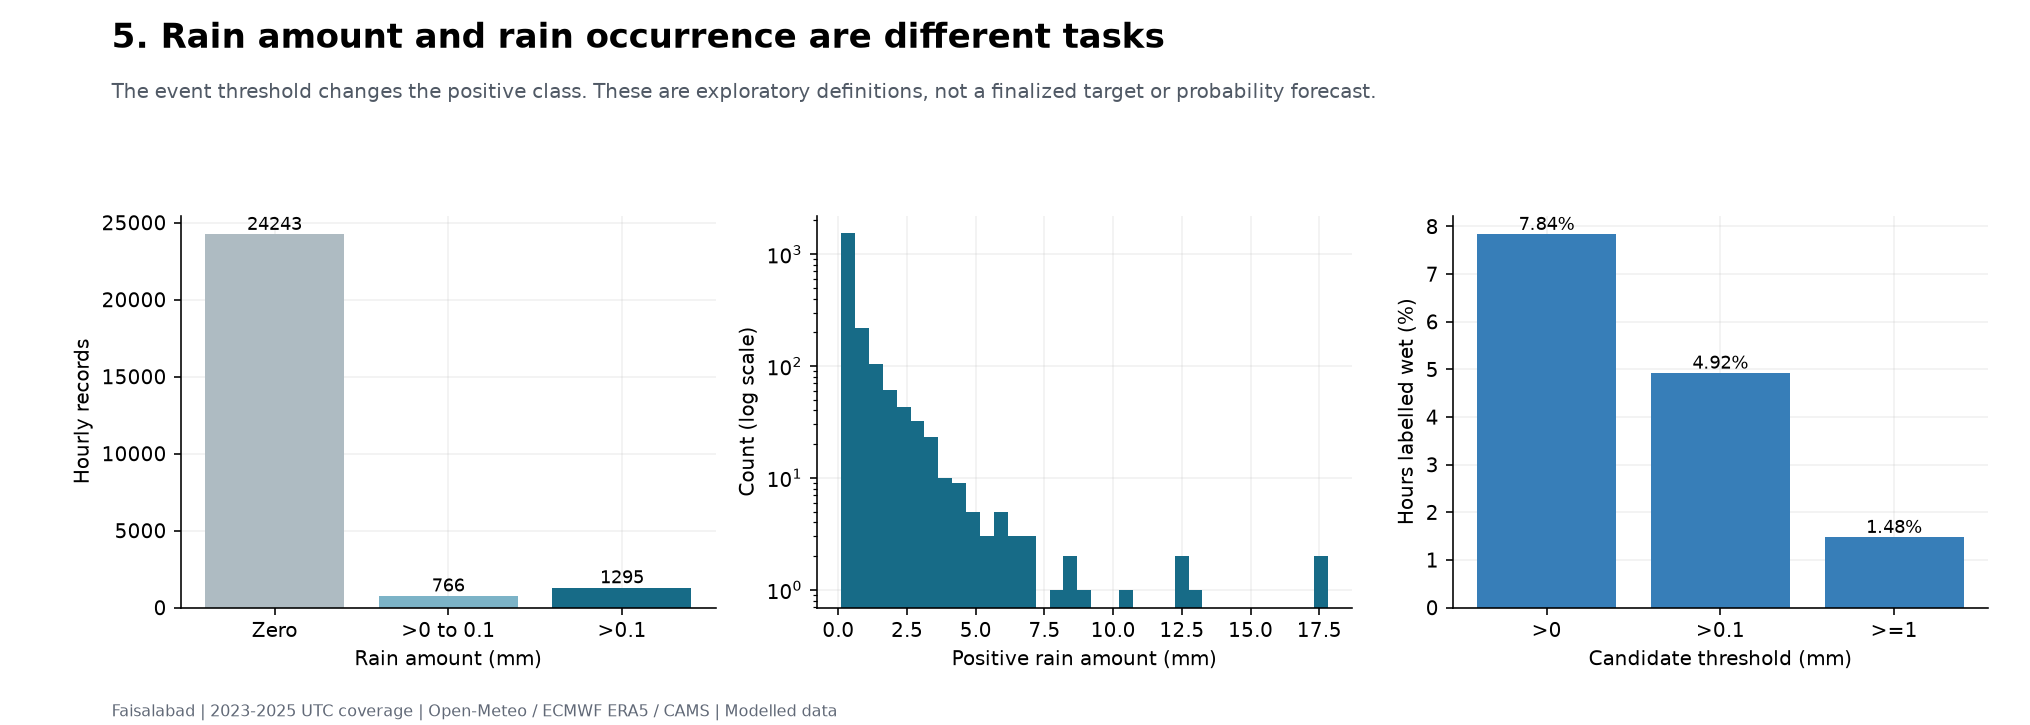

In [7]:
display(pd.read_csv(OUT / "tables/rain_thresholds.csv").round(3))
show("05_rain_occurrence.png")

## 7. Wind is a circular variable

North is both 0 and 360 degrees. The ordinary average of 359 and 1 is 180, which incorrectly points south. A later model can use sine/cosine components or wind vectors. We have not changed the raw degrees here.

The circular chart shows the direction the wind comes **from**. The radial height is the percentage of non-calm hours in each sector. Speeds below 0.5 m/s are excluded from direction counts using a provisional EDA cutoff; the speed histogram keeps them.


Hours below provisional calm cutoff: 797


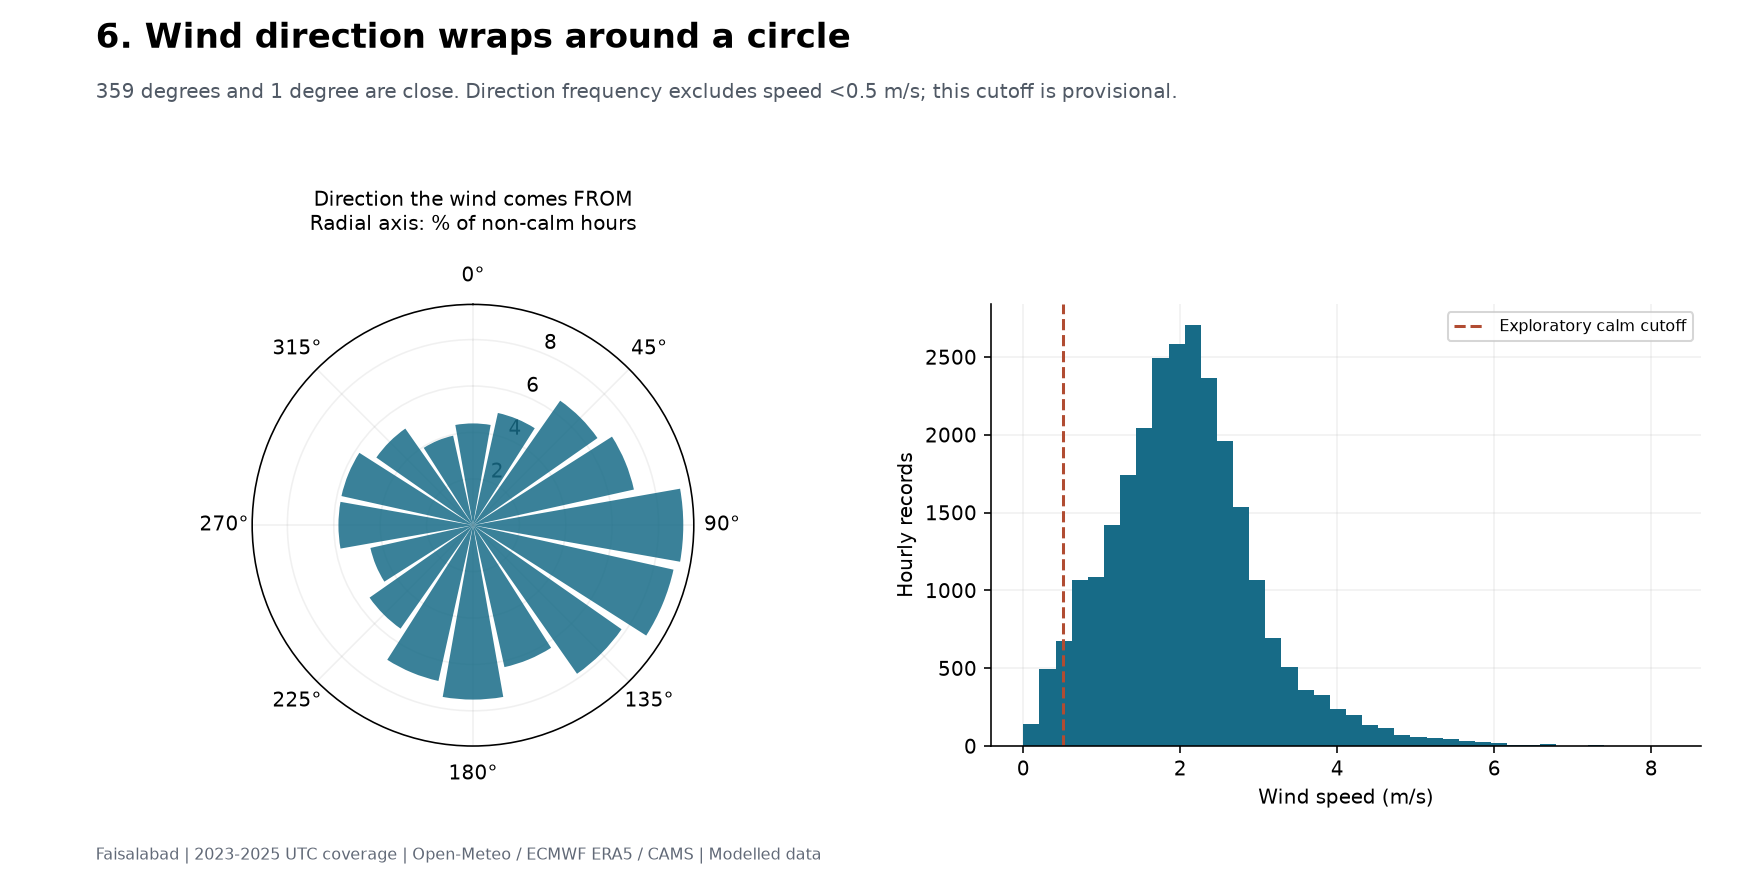

In [8]:
print("Hours below provisional calm cutoff:", facts["wind_calm_hours_below_0_5"])
show("06_wind_direction.png")

## 8. Correlation: association is not causation

**Pearson correlation** ranges from -1 to +1. Positive values mean two variables tend to move in the same direction; negative values mean they tend to move in opposite directions. Near zero means little linear association, not necessarily no relationship.

Seasonality and shared calculation methods can create strong relationships. AQI is derived from pollutant series, so correlation with PM2.5 is not evidence of an independent causal discovery. This chart describes simultaneous values, not the ability to predict values 24 hours ahead. Raw wind degrees are excluded.


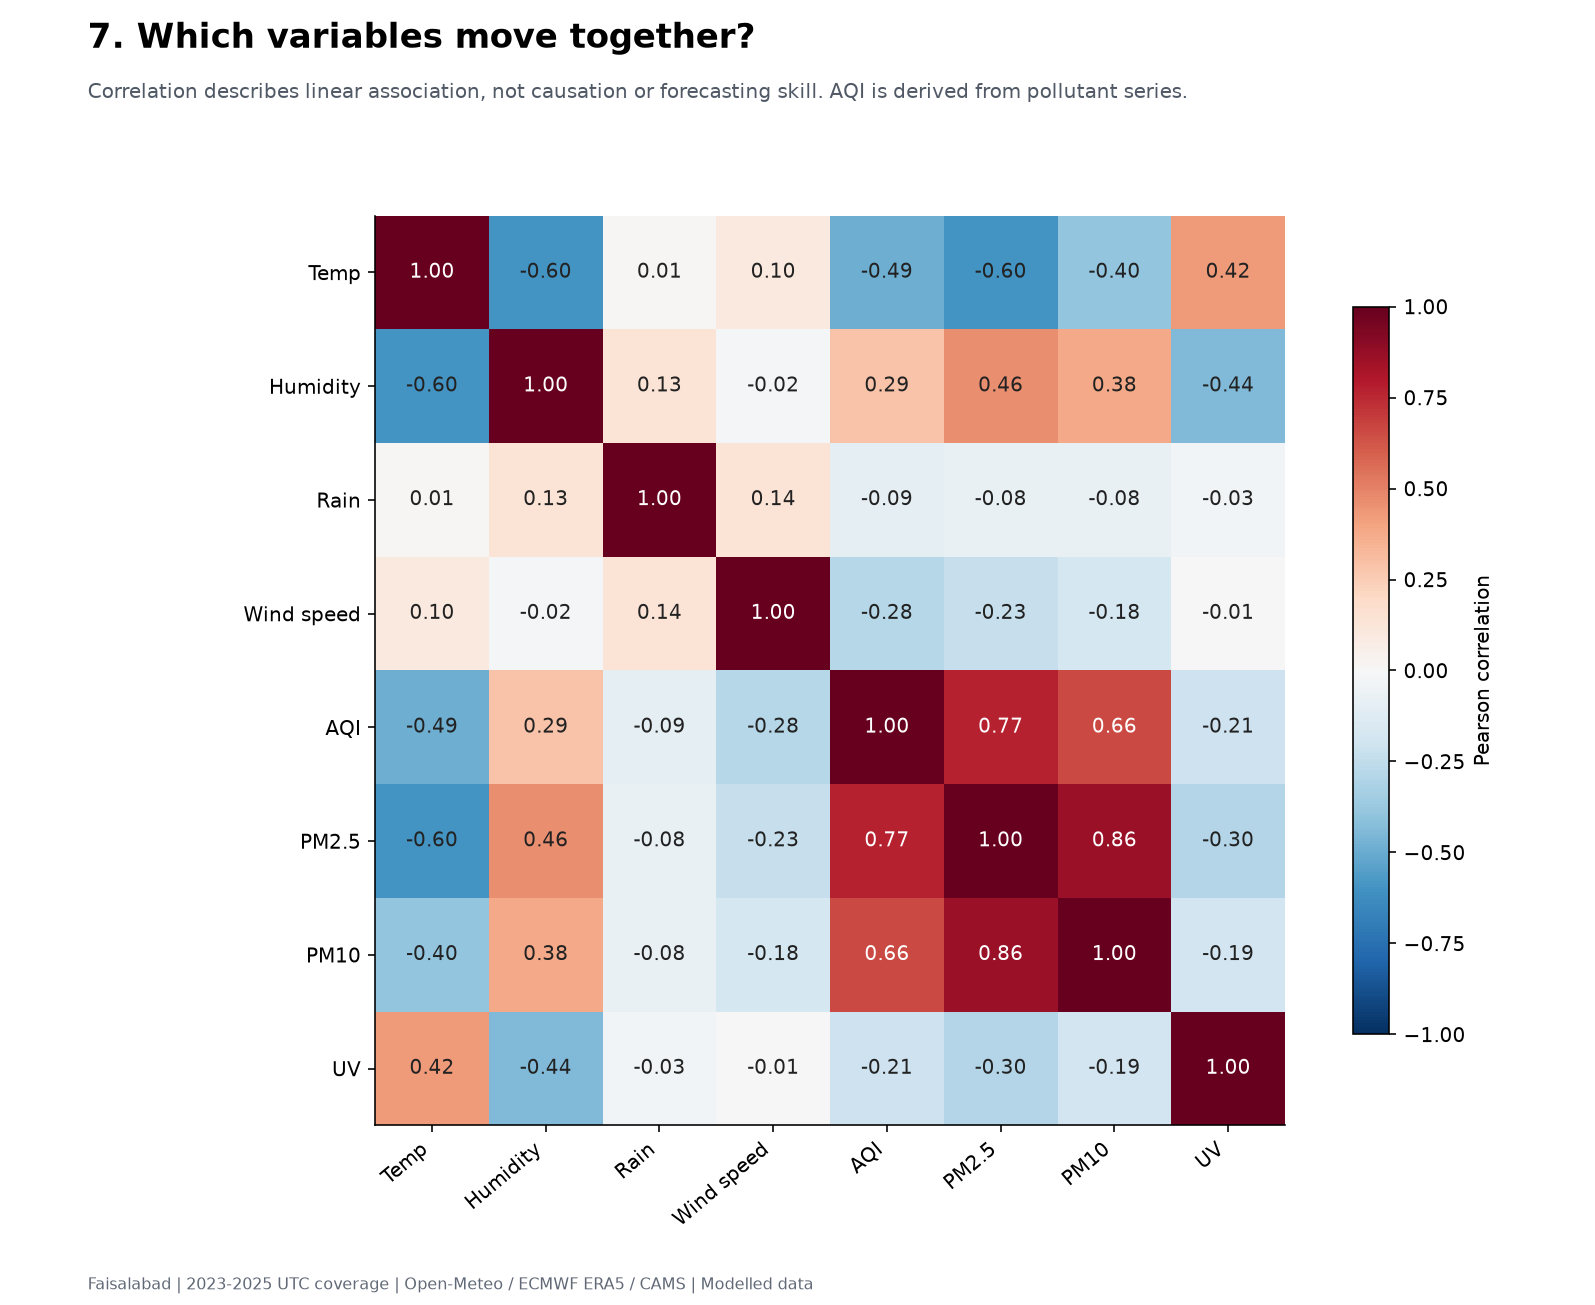

In [9]:
show("07_correlations.png")

## 9. Autocorrelation: compare a variable with its own past

A **lag** is a time offset. Lag 24 compares each hourly value with the value one day earlier. **Autocorrelation** is the correlation of a series with that shifted copy.

Peaks near 24-hour multiples support checking daily seasonal features and the required seasonal naive baseline. High autocorrelation can also come from broad seasonal trends and smooth provider output. It is not a baseline error score or proof of prediction quality. The calculation uses hourly data, not the daily-smoothed plot.


,temperature_2m,us_aqi,relative_humidity_2m,uv_index,wind_speed_10m,precipitation
lag_hours,,,,,,
1,0.986,0.996,0.965,0.931,0.884,0.765
24,0.975,0.836,0.894,0.964,0.287,0.130
48,0.958,0.726,0.833,0.949,0.131,0.036
72,0.947,0.681,0.801,0.942,0.114,0.010


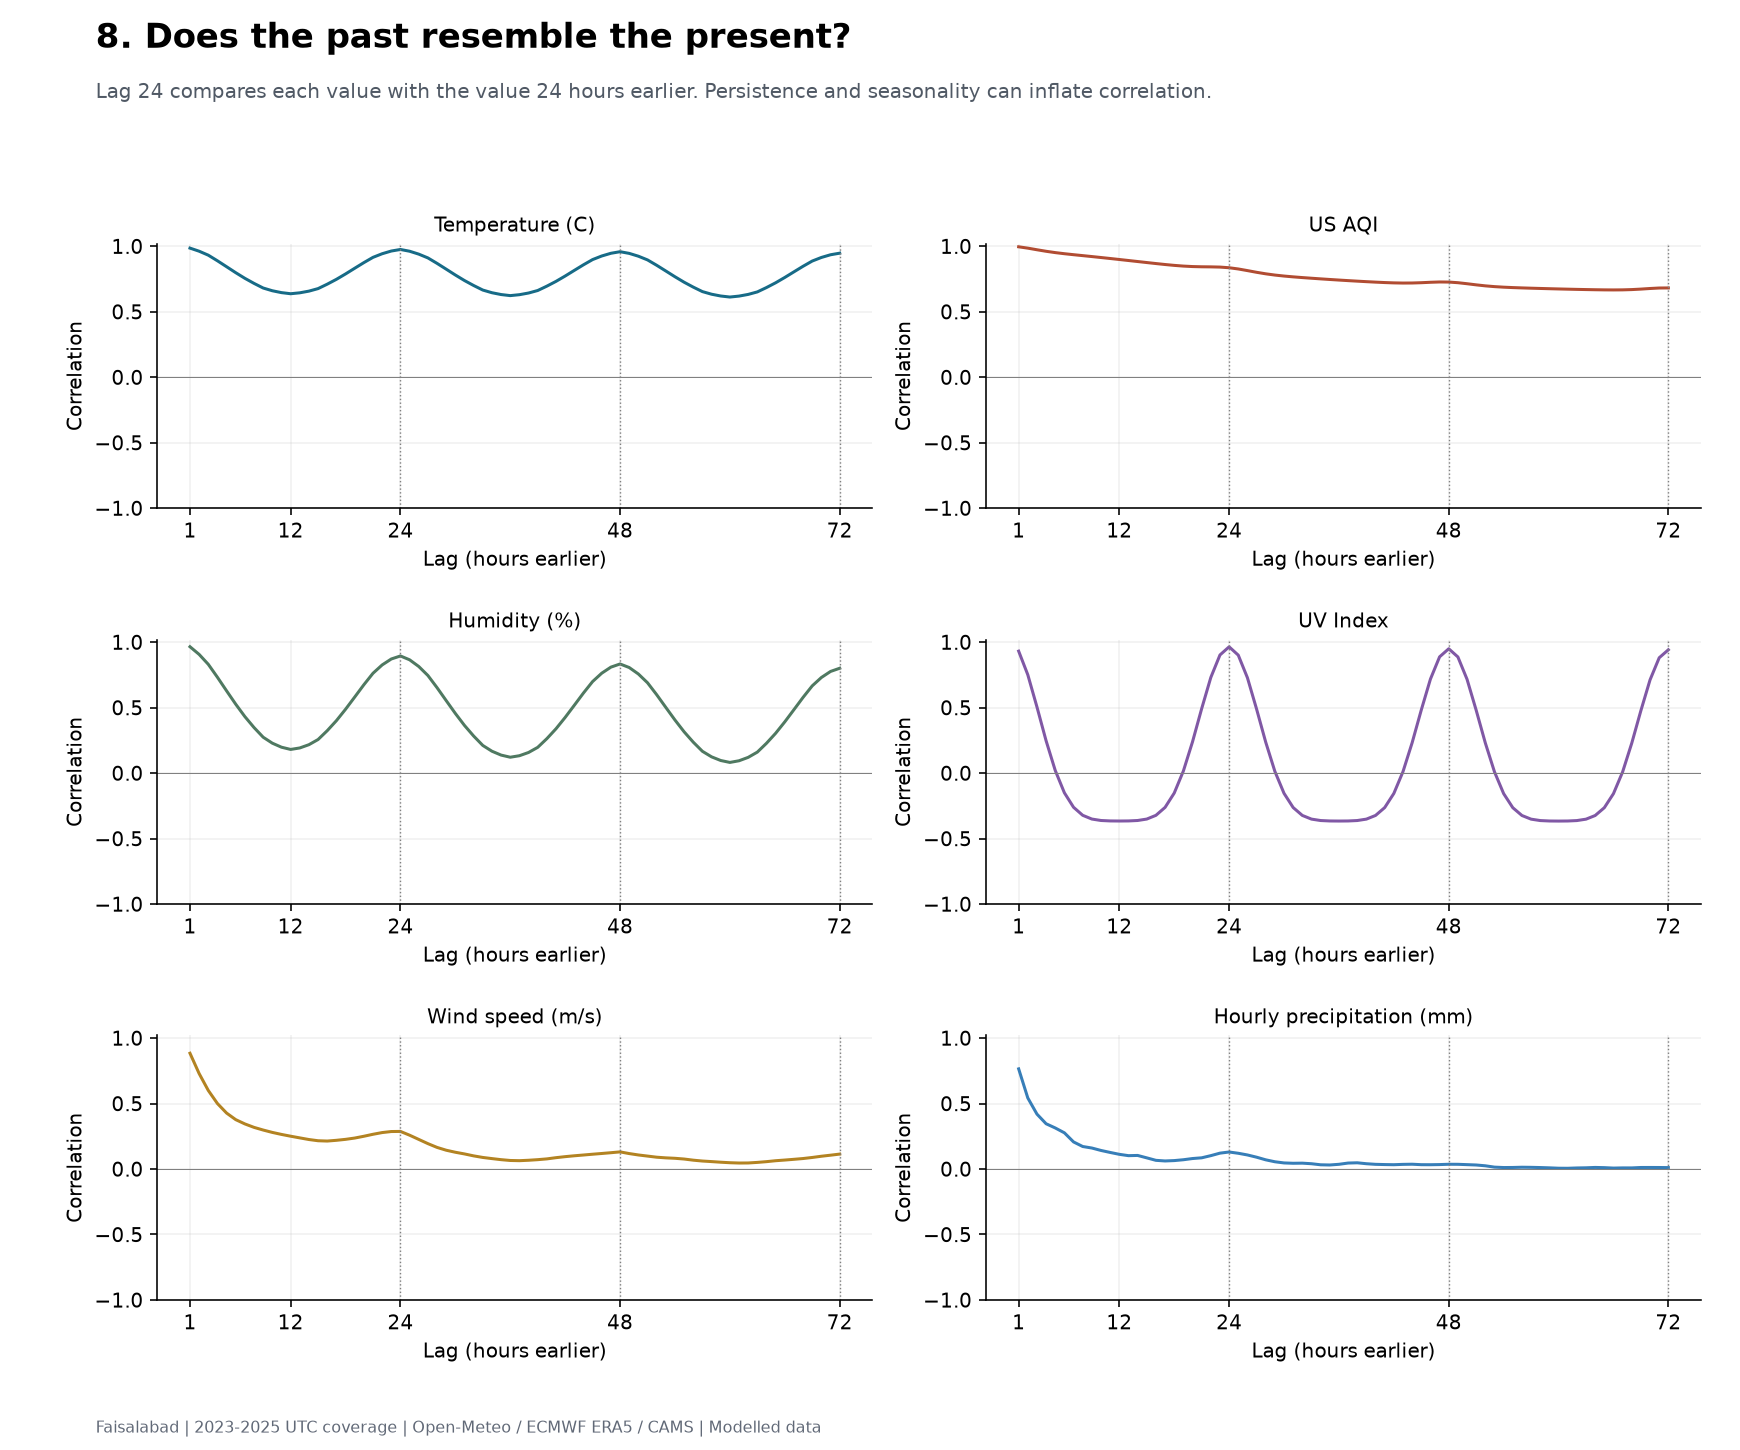

In [10]:
ac = pd.read_csv(OUT / "tables/autocorrelation.csv", index_col=0)
display(ac.loc[[1, 24, 48, 72]].round(3))
show("08_autocorrelation.png")

## 10. Investigate the 8.6 C cooling event

The dashed line marks **5 June 2024 at 17:00 Pakistan time**. Temperature falls from 36.9 to 28.3 C. At the same timestamp, humidity rises from 39% to 73%, rain increases from 0.1 to 2.3 mm, and wind speed rises from 2.26 to 6.58 m/s.

These aligned changes are consistent with rain-related cooling in the reanalysis. They do not independently prove a real local storm. Retain the observations and document the evidence rather than replacing the temperature merely because it is unusual.


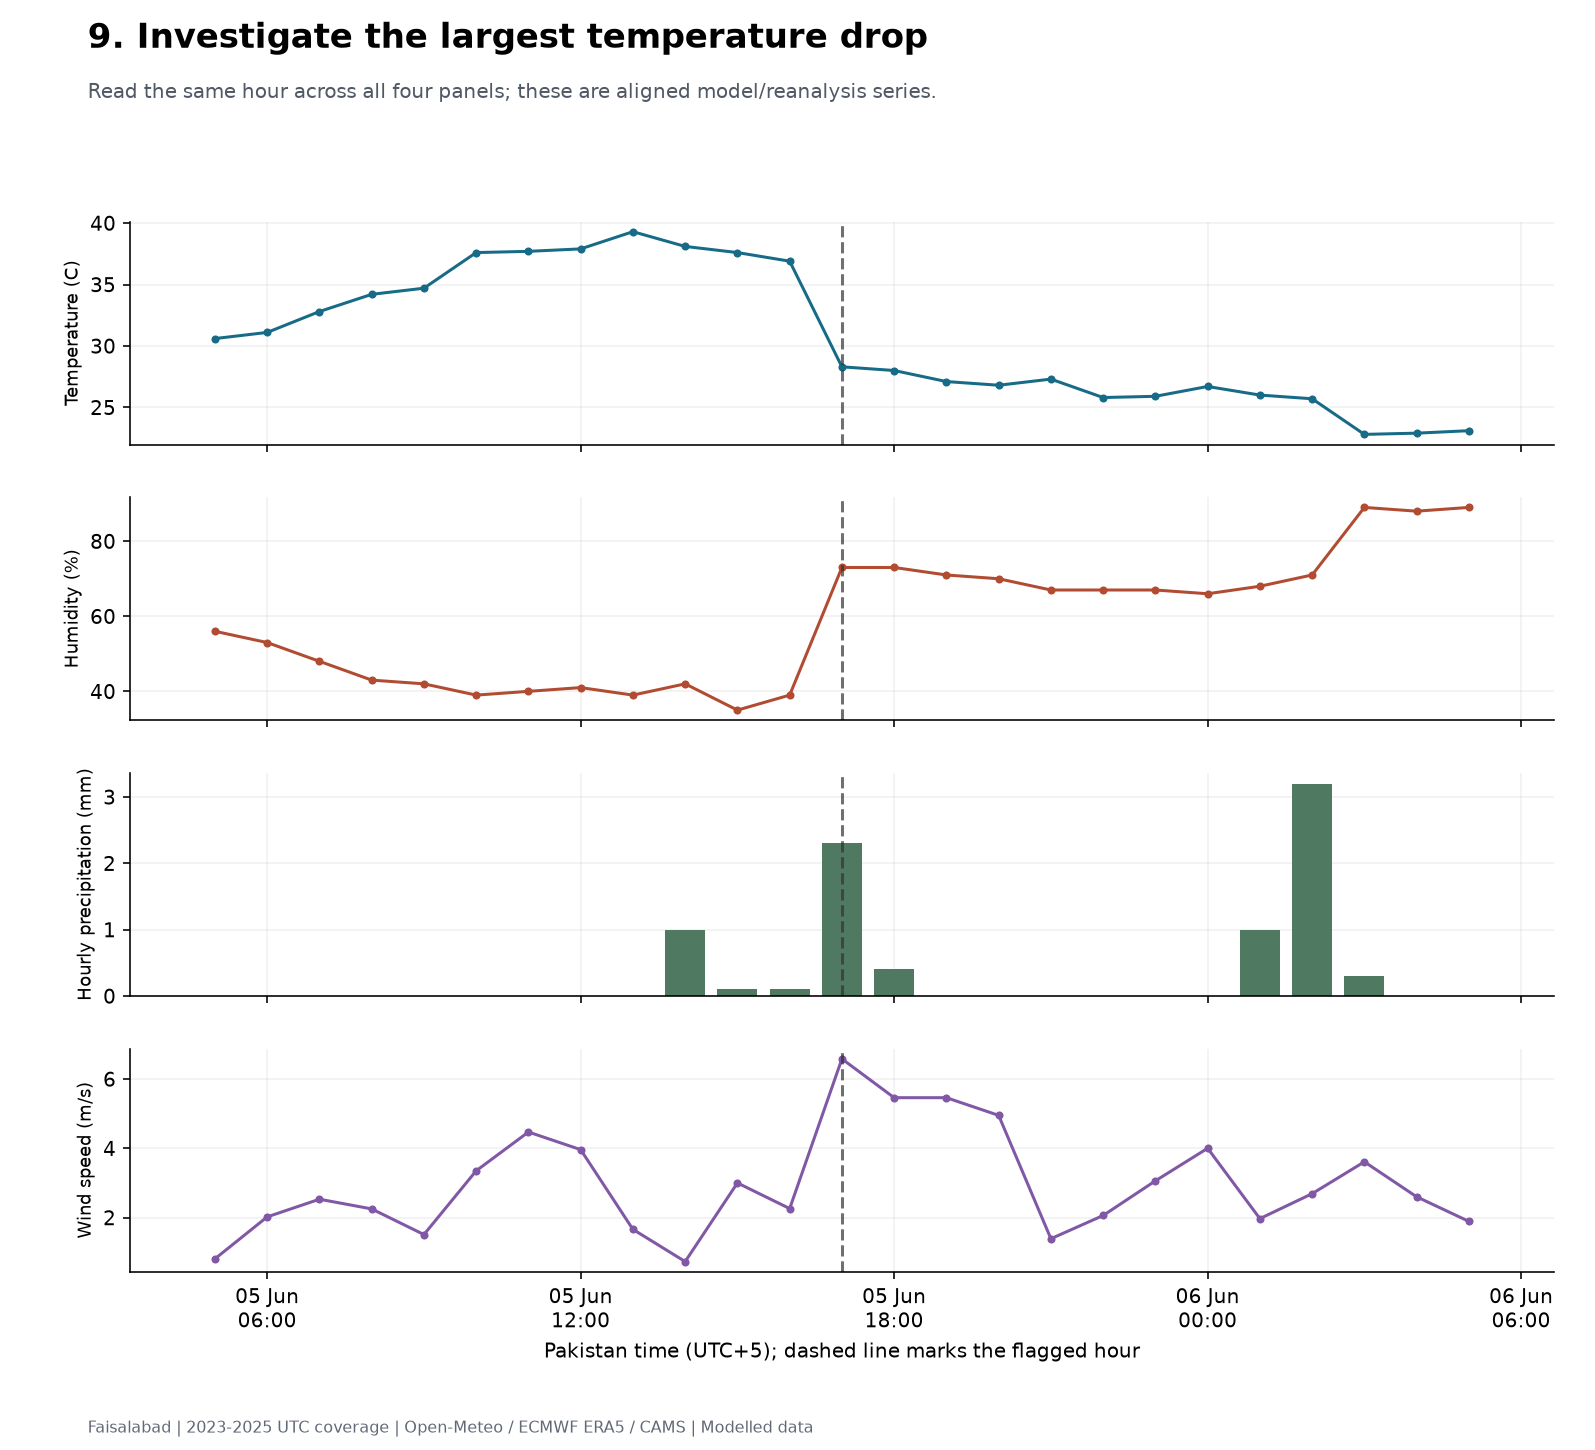

In [11]:
show("09_cooling_event.png")

## 11. Investigate sharp winter warming

The flagged hour is **26 January 2025 at 10:00 Pakistan time**. Temperature rises from 9.3 to 17.6 C while humidity drops from 60% to 36%, with no modelled rain in that hour.

The context is compatible with morning warming, but **226 of 242 changes of at least 6 C occur at 10:00 local time**. This repeated timing needs a source-processing investigation, not just an explanation of one selected day. A supplementary one-day ERA5-Land comparison shows a smaller 5.0 C rise in the corresponding hour. The products are related, so this is not independent verification.

Do not claim that sunlight or fog clearing has been confirmed: neither radiation nor fog observations were collected. Retain the observations and flag them for sensitivity analysis. The second plot below shows the broader timing pattern. To reproduce its supplementary panel, first run `python scripts/check_warming_source.py`.


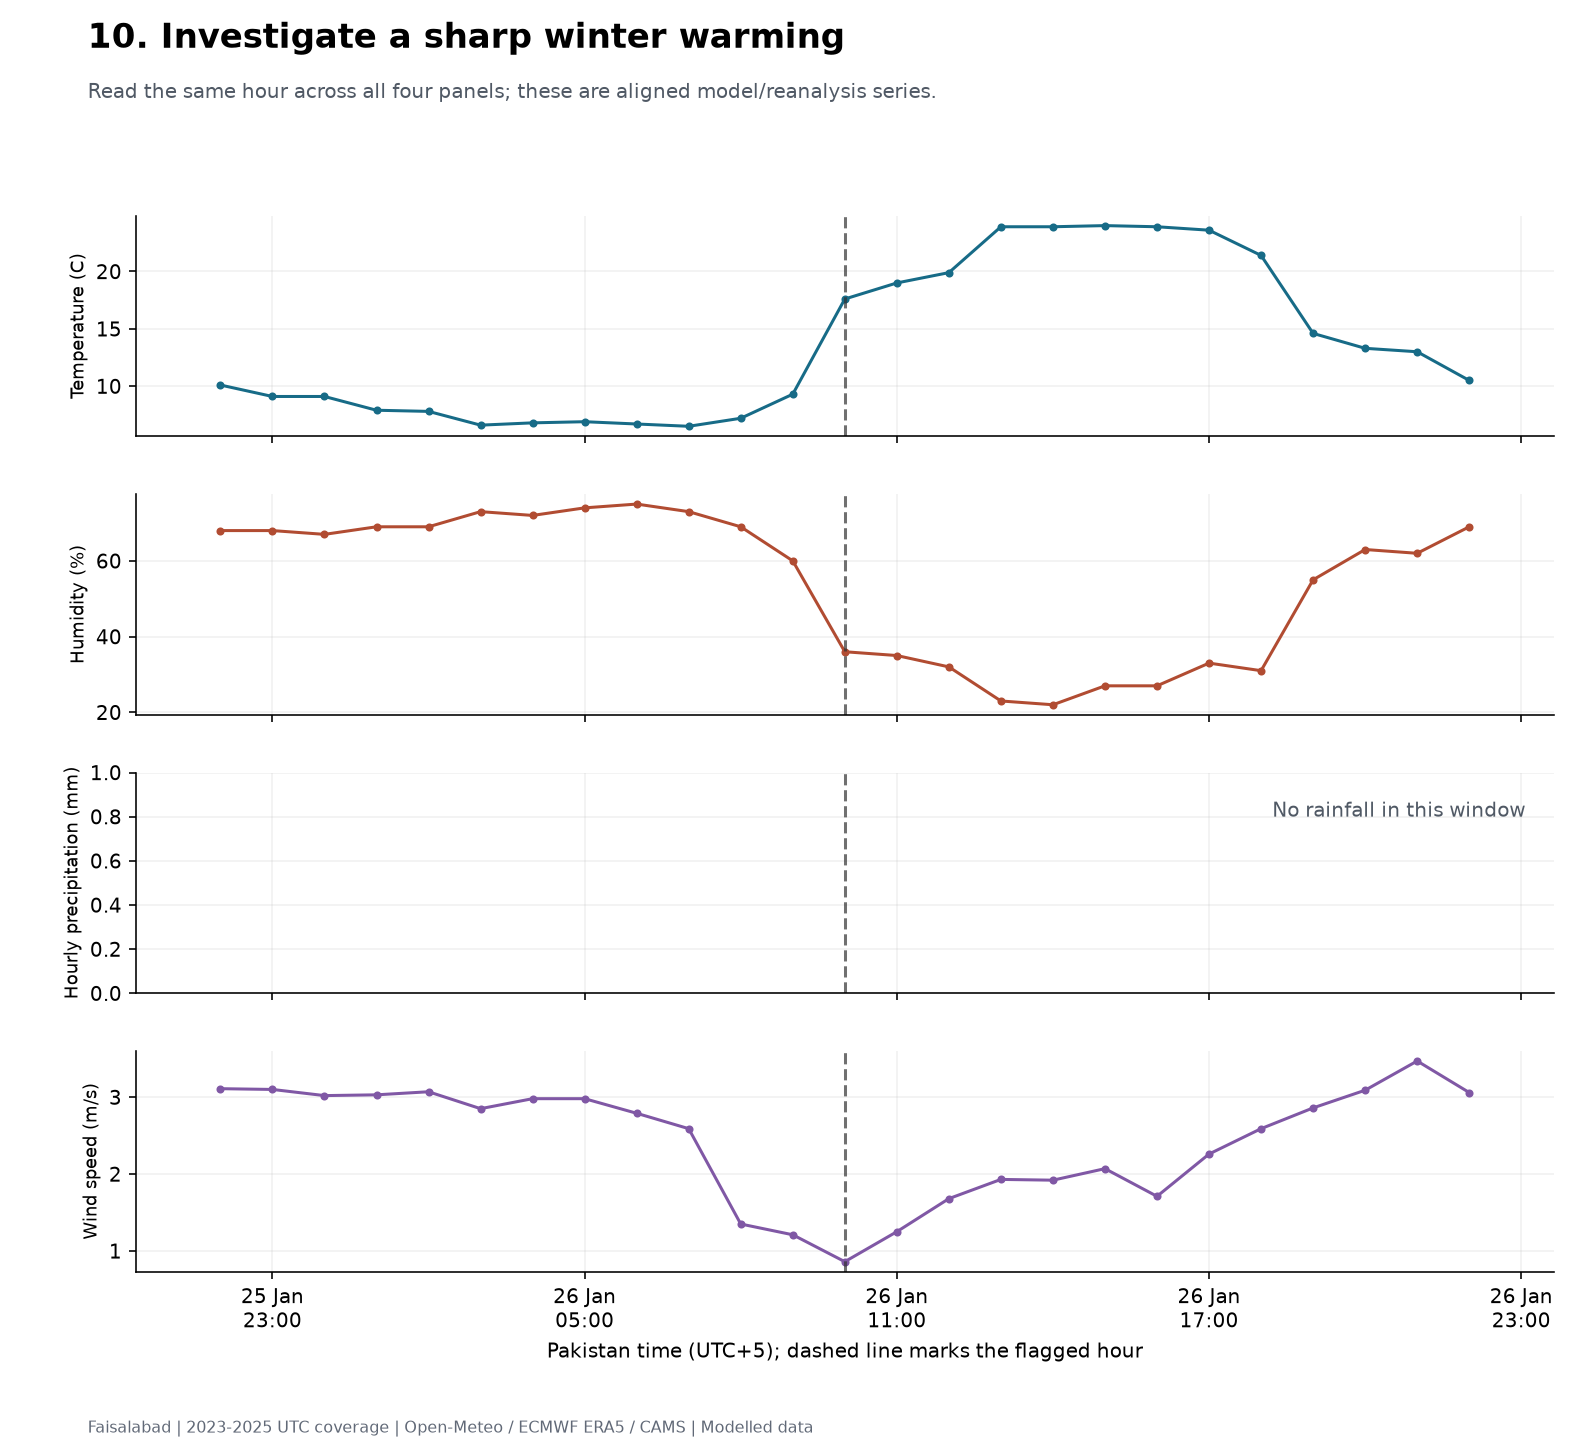

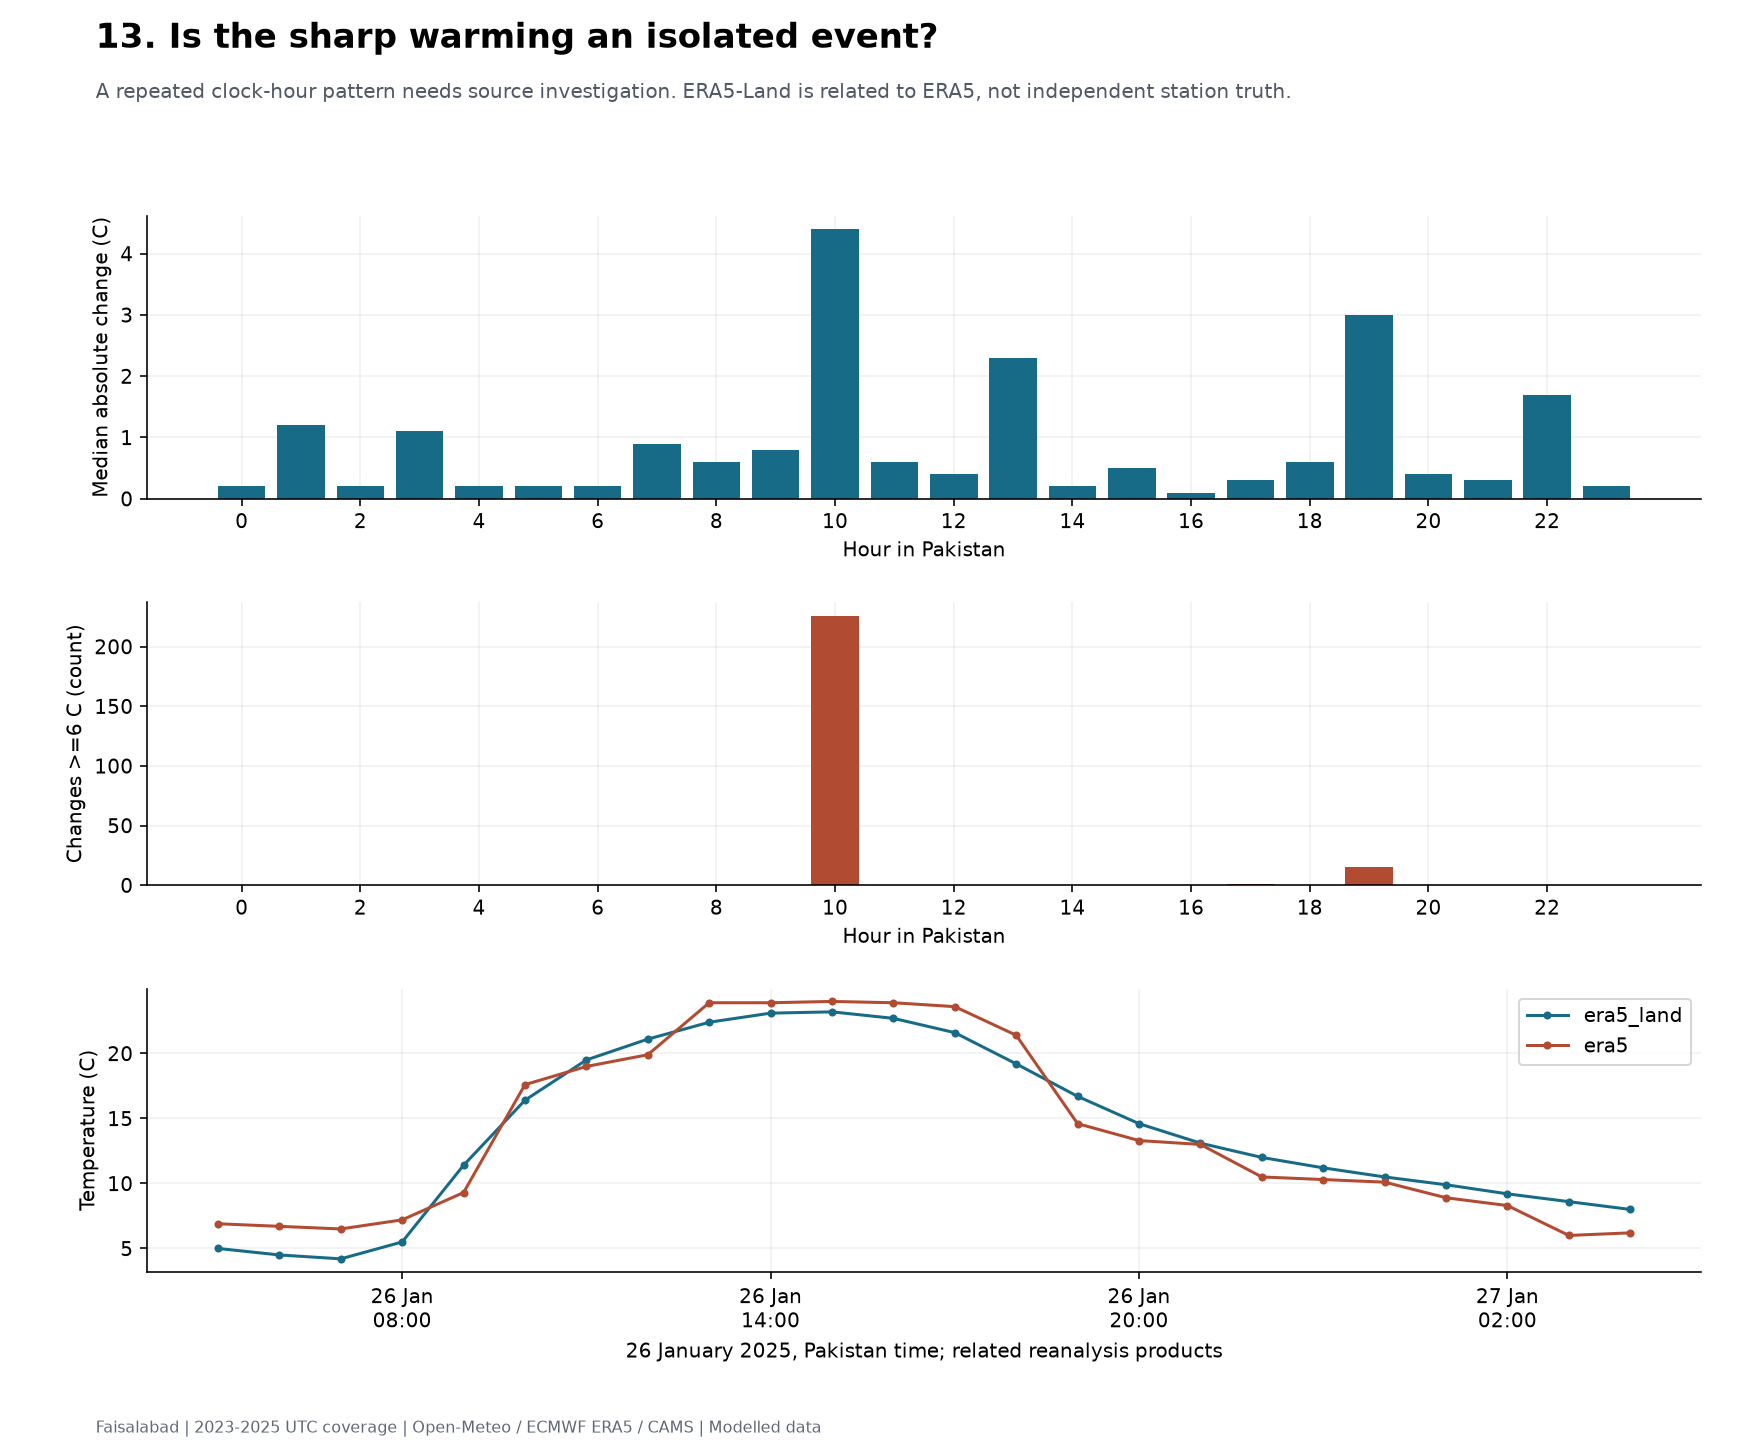

In [12]:
show("10_warming_event.png")
show("13_temperature_timing.png")

## 12. Investigate the 21-hour AQI plateau

A **plateau** is a flat stretch of a series. Check whether other columns are also frozen. If they vary, the flat AQI is not a duplicated block of entire records.

The provider documents pollutant averaging windows in AQI calculations, and the returned AQI is integer-valued. Those facts make smoothing/rounding plausible explanations, but we have not reconstructed the full provider calculation or identified the dominant pollutant. Keep this as an unresolved source characteristic, not a proven sensor outage or a confirmed rounding effect.


,start,end,hours,value,pm2_5_range,pm10_range,distinct_full_rows
0,2024-02-18T23:00:00+05:00,2024-02-19T19:00:00+05:00,21,154.0,"[33.8, 94.5]","[62.6, 157.4]",21


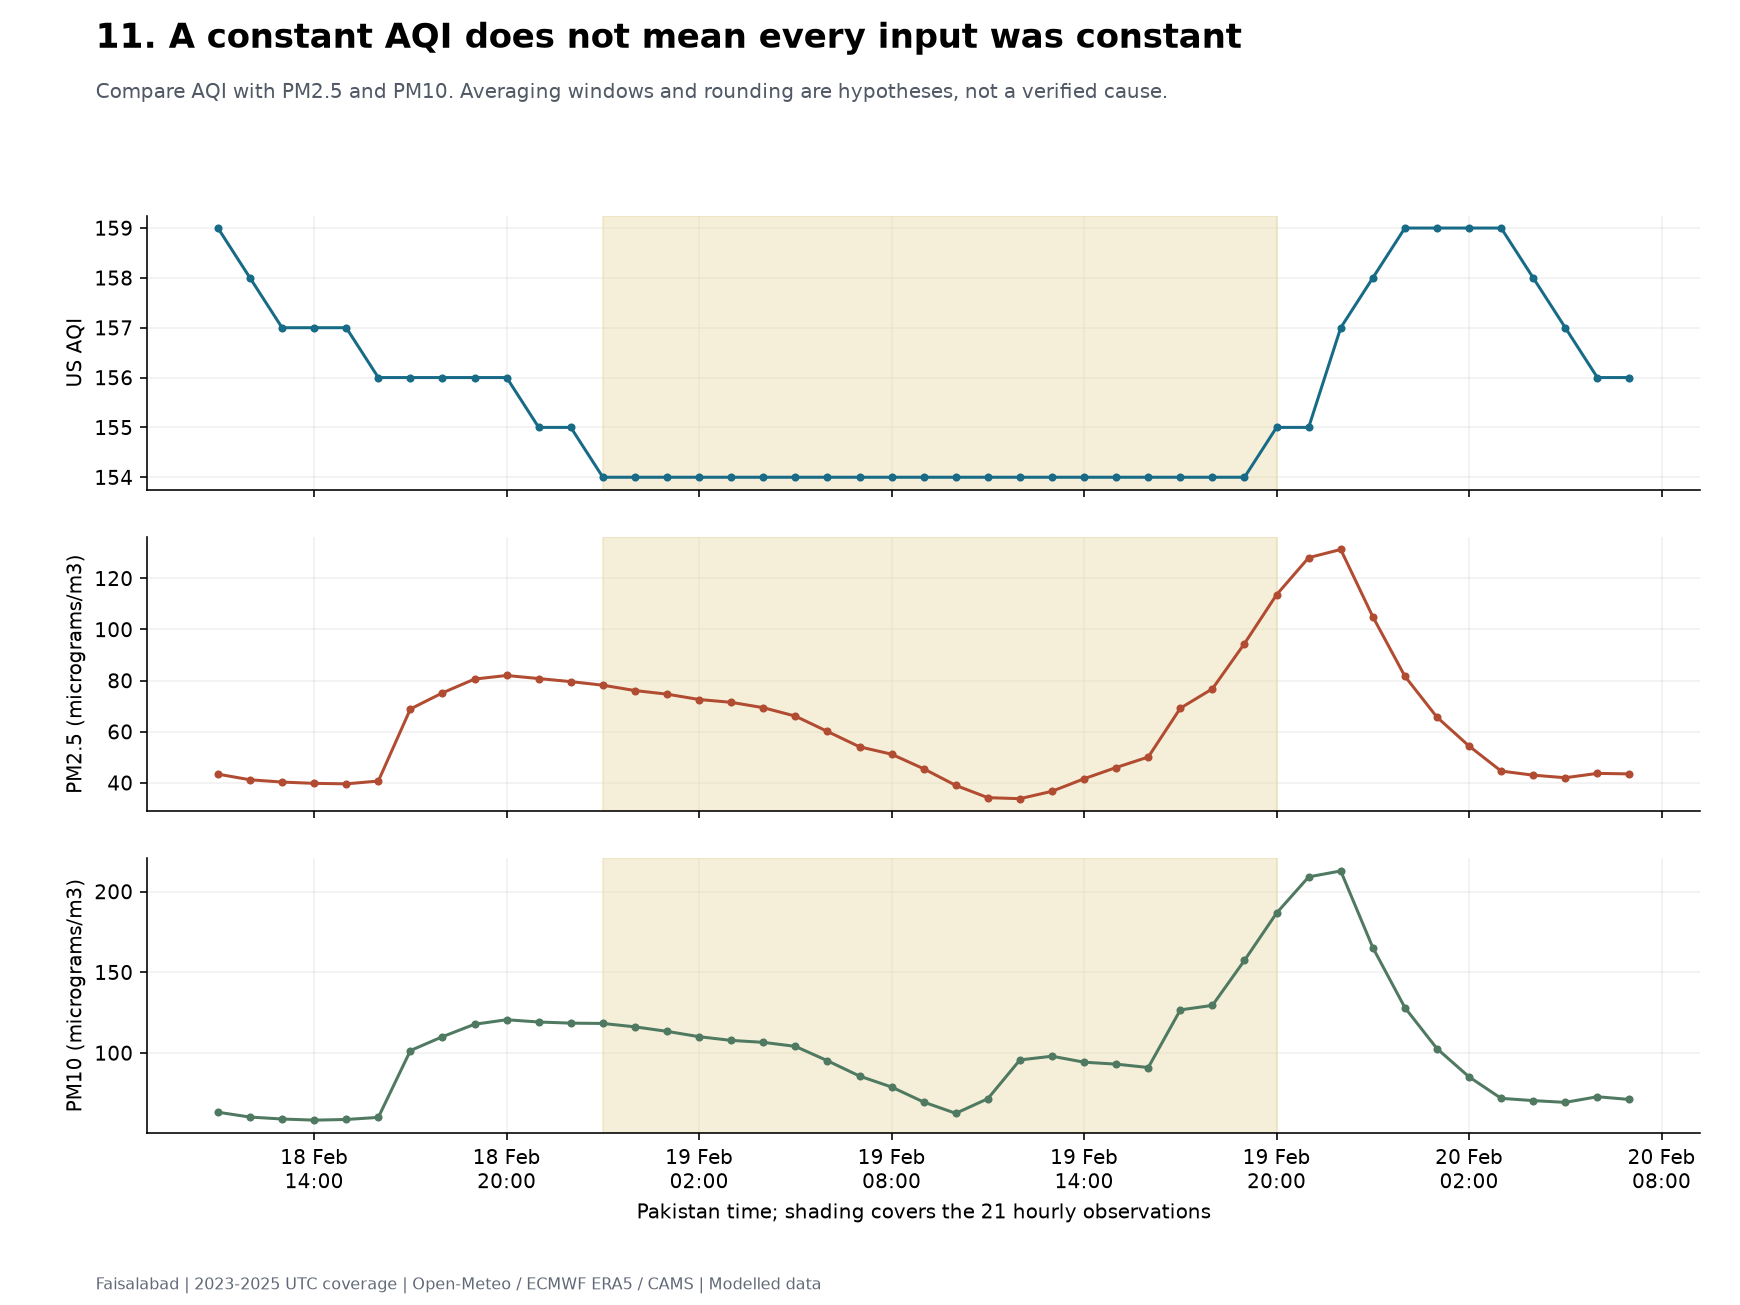

In [13]:
display(pd.DataFrame([facts["aqi_plateau"]]))
show("11_aqi_plateau.png")

## 13. Investigate long runs of zero

The top panel shows the longest zero-rain stretch and surrounding days. Complete timestamps and changing non-rain fields argue against a full-record collection freeze; they cannot prove the rain estimates are accurate.

The bottom panel checks UV zeros by local clock hour. Nighttime zero UV is expected. A positive UV at an unexpected clock hour would be a review flag, not an automatic deletion. We use 00:00-03:59 as a simple core-night check and do not calculate solar elevation.


Longest zero-rain run: {'start': '2025-10-06T20:00:00+05:00', 'end': '2025-12-31T06:00:00+05:00', 'hours': 2051, 'value': 0.0}
Positive UV values in core-night hours: 0 of 4384


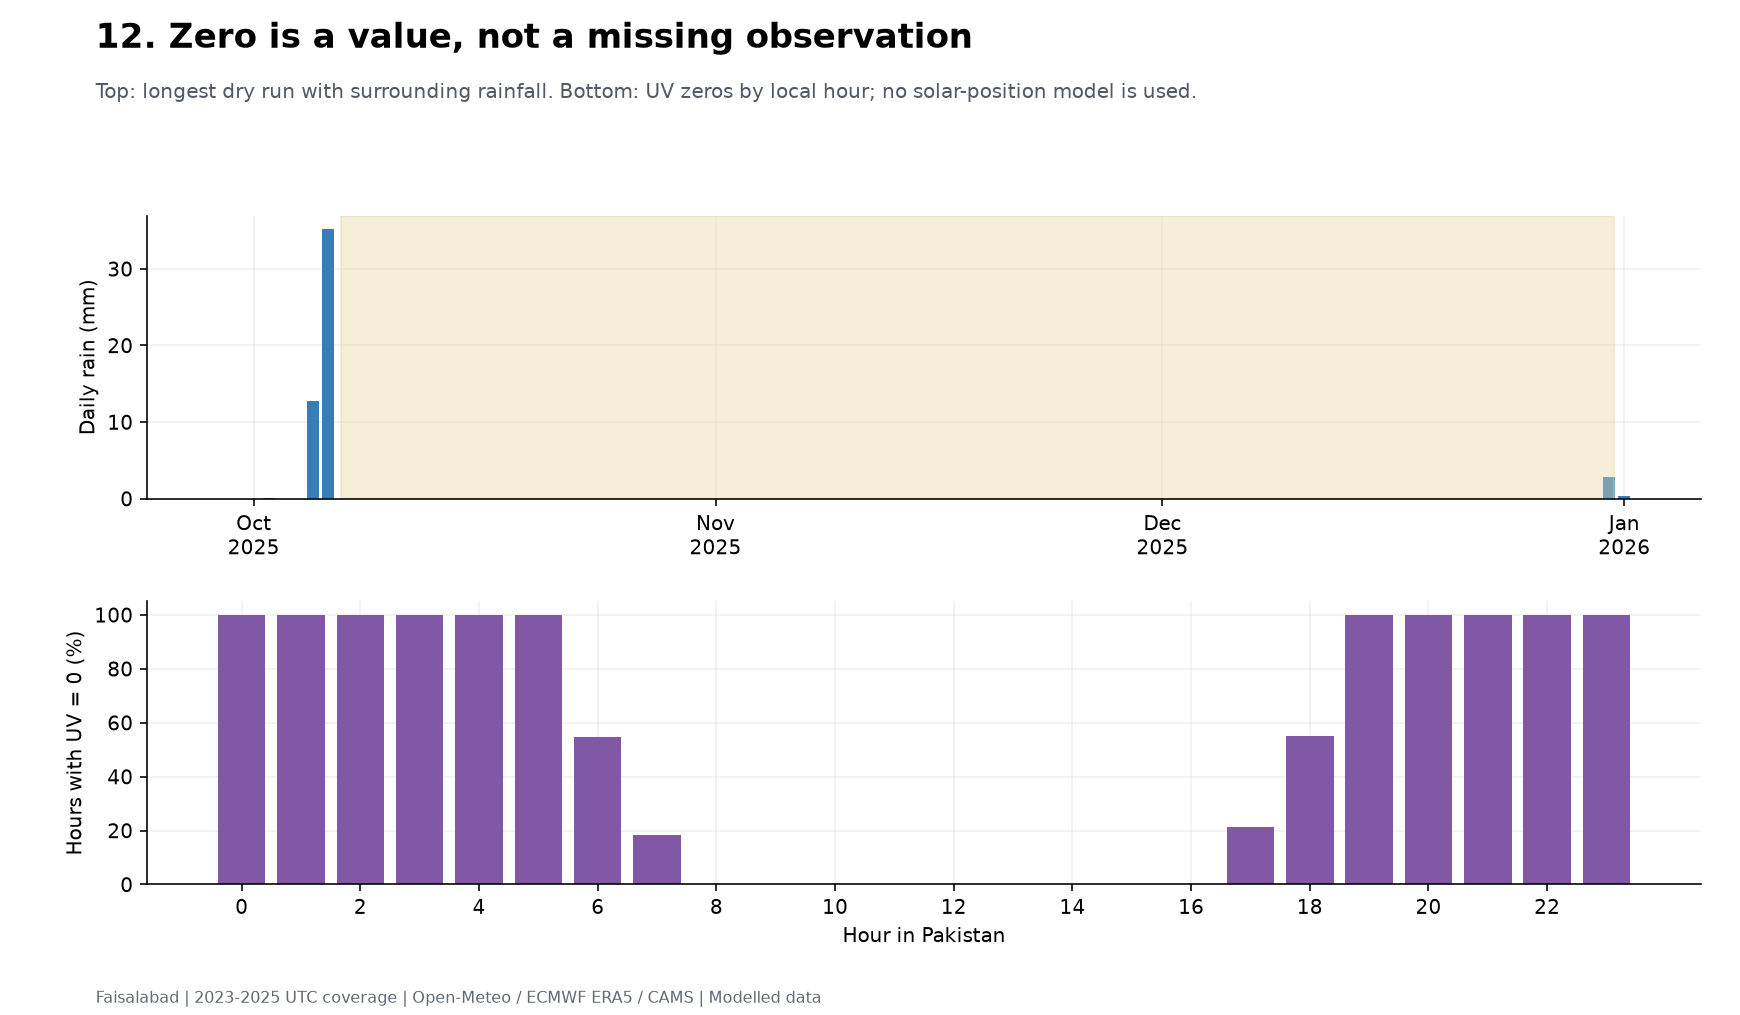

In [14]:
print("Longest zero-rain run:", facts["longest_dry_run"])
print("Positive UV values in core-night hours:", facts["uv_positive_core_night_hours"], "of", facts["uv_core_night_hours"])
show("12_zero_values.png")

## 14. Decisions before modelling

- Keep raw data unchanged. No gap filling, clipping, or outlier removal has been justified by this EDA.
- Retain the cooling event; retain and review the sharp winter warming and AQI plateau.
- Treat rain amount and rain probability separately, and document the event definition before training.
- Use local hour and seasonal features; evaluate their value on later validation data.
- Handle wind direction circularly and define calm-wind policy.
- Align historical and live source definitions and availability times before creating features. Reanalysis must not be treated as if it was available instantly.
- All of 2023-2025 was inspected here. Reserve a separate uninspected later period for a genuine final test.

Detailed findings and open questions are in `docs/EDA.md`. No model has been fitted, and EDA alone does not complete the project.

Sources: [Open-Meteo weather documentation](https://open-meteo.com/en/docs/historical-weather-api), [air-quality documentation](https://open-meteo.com/en/docs/air-quality-api). Data attribution: Open-Meteo, ECMWF/Copernicus ERA5, and CAMS. Derived figures retain the source limitations.
